# Compare simple vs. extended ERM (parallel)

Starting 10 simulation trials on all cores...


Running all trials:   0%|          | 0/10 [00:00<?, ?it/s]

Starting divide-and-conquer search for 2 change points...
fit score: 514.9675, gamma * log-penalty term: 8.0262 (gamma=0.5)
Change points: [ 945 1276], Number of change points: 2, L_tilde: 3, n: 2500
Starting divide-and-conquer search for 2 change points...
fit score: 343.9774, gamma * log-penalty term: 7.8029 (gamma=0.5)
Change points: [ 725 1005], Number of change points: 2, L_tilde: 3, n: 2000
Starting divide-and-conquer search for 2 change points...
fit score: 669.3724, gamma * log-penalty term: 8.2086 (gamma=0.5)
Change points: [1188 1510], Number of change points: 2, L_tilde: 3, n: 3000
Starting divide-and-conquer search for 2 change points...
fit score: 745.5404, gamma * log-penalty term: 8.3628 (gamma=0.5)
Change points: [1097 1765], Number of change points: 2, L_tilde: 3, n: 3500
Starting divide-and-conquer search for 2 change points...
fit score: 981.8691, gamma * log-penalty term: 8.6142 (gamma=0.5)
Change points: [2106 2848], Number of change points: 2, L_tilde: 3, n: 4500


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 18.16it/s]


100%|██████████| 1/1 [00:00<00:00, 18.17it/s]


100%|██████████| 1/1 [00:00<00:00, 16.58it/s]


100%|██████████| 1/1 [00:00<00:00, 17.50it/s]


100%|██████████| 1/1 [00:00<00:00, 15.30it/s]


100%|██████████| 1/1 [00:00<00:00, 16.34it/s]


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 21.14it/s]


100%|██████████| 1/1 [00:00<00:00, 21.87it/s]


fit score: 426.6383, gamma * log-penalty term: 0.0055 (gamma=0.005)
Change points: [], Number of change points: 0, L_tilde: 1, n: 1500
fit score: 730.0429, gamma * log-penalty term: 0.0055 (gamma=0.005)
Change points: [], Number of change points: 0, L_tilde: 1, n: 2000
fit score: 1238.5045, gamma * log-penalty term: 0.0055 (gamma=0.005)
Change points: [], Number of change points: 0, L_tilde: 1, n: 3000
fit score: 1363.9537, gamma * log-penalty term: 0.0055 (gamma=0.005)
Change points: [], Number of change points: 0, L_tilde: 1, n: 3500
fit score: 949.3925, gamma * log-penalty term: 0.0055 (gamma=0.005)
Change points: [], Number of change points: 0, L_tilde: 1, n: 2500
fit score: 1816.0121, gamma * log-penalty term: 0.0055 (gamma=0.005)
Change points: [], Number of change points: 0, L_tilde: 1, n: 4000
fit score: 259.6862, gamma * log-penalty term: 0.0055 (gamma=0.005)
Change points: [], Number of change points: 0, L_tilde: 1, n: 1000
fit score: 1947.5501, gamma * log-penalty term: 0.00

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 14.80it/s]


100%|██████████| 1/1 [00:00<00:00, 16.72it/s]


... (7 outputs left out)

Penalized Search over L: 100%|██████████| 3/3 [00:02<00:00,  1.17it/s]


100%|██████████| 1/1 [00:00<00:00, 14.29it/s]


Starting divide-and-conquer search for 1 change points...
fit score: 1881.2319, gamma * log-penalty term: 0.0486 (gamma=0.005)
Change points: [3843], Number of change points: 1, L_tilde: 2, n: 5500


Penalized Search over L: 100%|██████████| 3/3 [00:04<00:00,  1.60s/it]


Aggregating results...
Plotting results...


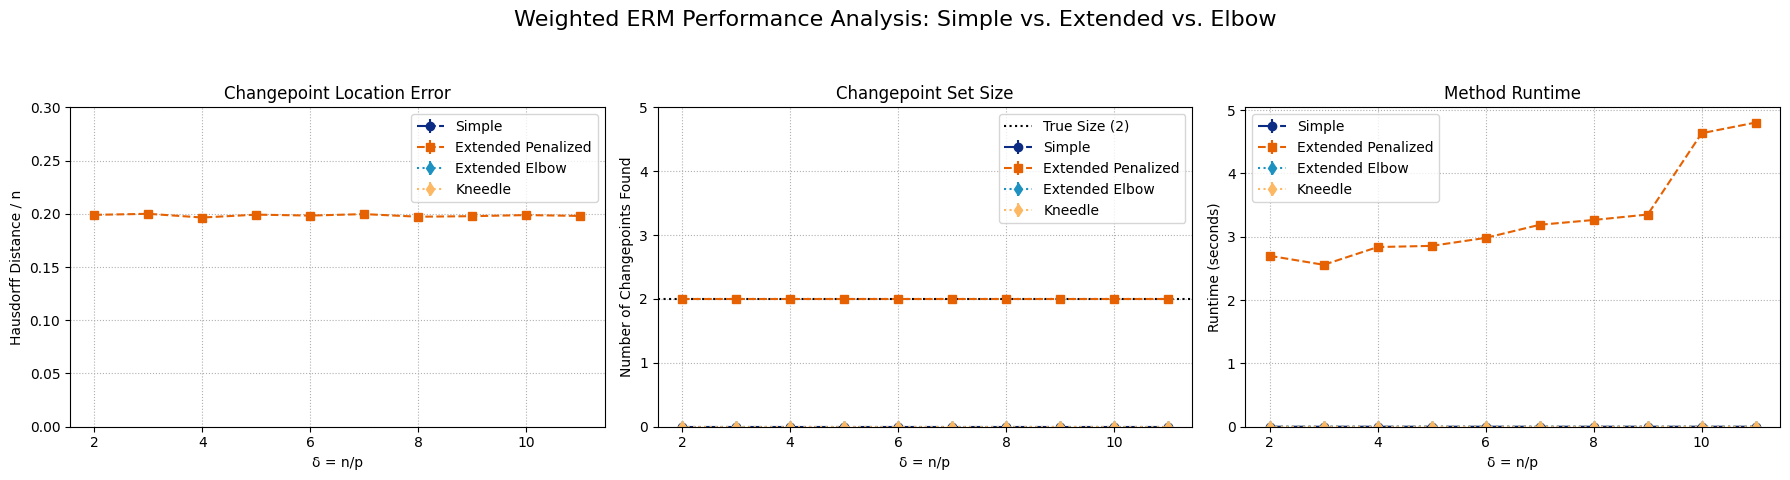

In [ ]:
from WERM.signal_priors import GaussianSignal
import WERM.model
import WERM.general_fixed_point_eqns as fp
import WERM.performance_measures
import WERM.estimators
from WERM.config import η_to_ψ
import numpy as np
import jax.numpy as jnp
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
from functools import partial
from tqdm.auto import tqdm
import time
from joblib import Parallel, delayed
from sklearn.linear_model import LinearRegression

# -----------------------------------------------------------------------------
# 1. Helper Function for a Single Parallel Job
# -----------------------------------------------------------------------------

def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, gamma_candidates):
    """
    Executes a single simulation trial for a given delta.
    This function is designed to be called in parallel by joblib.
    """
    # Unpack parameters for this specific job
    i, δ, j = params

    # --- Setup based on delta ---
    n = int(δ * p)
    Delta = lambda n: int(n / 10)
    true_chgpt_locations_fn = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)

    # Signal Prior Setup
    κ = 1.0
    B̃_cov = κ**2 * δ * np.eye(L)
    # Add some nontrivial correlation structure to the covariance matrix
    for k_ in range(L):
        for l_ in range(L):
            if k_ != l_:
                B̃_cov[k_, l_] = κ**2 * δ * 0.0 * (k_ + 1) * (l_ + 1) / (L * (L - 1))
    # Ensure the covariance matrix is positive definite
    B̃_cov = (B̃_cov + B̃_cov.T) / 2
    B̃_cov = jnp.array(B̃_cov)
    signal_prior = GaussianSignal(B̃_cov)

    # --- Data Generation for this trial ---
    B̃ = signal_prior.sample(p)
    X = nprandom.normal(0, np.sqrt(1/n), (n, p))
    # ε = nprandom.normal(0, 1, size=(n,)) * noise_std
    ε = np.random.standard_t(5, size=(n, )) * noise_std # For Huber loss, use t-distribution for noise
    
    true_chgpts = true_chgpt_locations_fn(n)
    C_true = η_to_ψ(true_chgpts, n) if true_chgpts.size > 0 else np.zeros(n).astype(int)
    Θ = X @ B̃
    y = jax.vmap(WERM.model.q_linear_model, in_axes=(0, 0, 0))(Θ, C_true, ε)


    # --- Run Estimators ---
    trial_results = {}

    # Method 1: Simple Weighted ERM
    start_time = time.time()
    # gamma_hat_1 = WERM.estimators.weighted_ermCV(X, y, M, L, Delta(n), gamma_candidates=gamma_candidates, L_is_upper_bound=True, brute_force=True)
    # gamma_hat_1 = 100 * 2 * noise_std**2 # Oracle value for gamma
    gamma_hat_1 = 10.0
    # chgpts_simple = WERM.estimators.weighted_erm(X=X, y=y, M=M, L=L, Delta_n=Delta(n), gamma=gamma_hat_1, L_is_upper_bound = True, return_B_hat=False, brute_force=False)
    chgpts_simple = np.array([])
    trial_results['runtime_simple'] = time.time() - start_time
    trial_results['haus_simple'] = (1/n) * WERM.performance_measures.hausdorff(chgpts_simple, true_chgpts)
    trial_results['size_simple'] = len(chgpts_simple[chgpts_simple != -1])

    # Method 2: Extended Penalized ERM
    start_time = time.time()
    gamma_hat_2 = 0.005  # Example gamma value, can be tune
    # best_gamma, chgpts_ext = WERM.estimators.weighted_erm_extended_penalizedCV(X=X, y=y, M=M, L=L, Delta_n=Delta(n), gamma_candidates=gamma_candidates, brute_force=False, M_scorer = M_scorer, num_folds = 5)
    chgpts_ext, candidate_scores = WERM.estimators.weighted_erm_extended_penalized(X=X, y=y, M=M, L=L, Delta_n=Delta(n), gamma=gamma_hat_2, brute_force=False, gof_output=True)
    # print(f"Best gamma for ext, trial {i}, δ={δ}: {best_gamma}")

    trial_results['runtime_ext'] = time.time() - start_time
    trial_results['haus_ext'] = (1/n) * WERM.performance_measures.hausdorff(chgpts_ext, true_chgpts)
    trial_results['size_ext'] = len(chgpts_ext[chgpts_ext != -1])

    # Method 3: Extended Elbow ERM
    start_time = time.time()
    # chgpts_elbow = WERM.estimators.weighted_erm_extended_elbow(X=X, y=y, M=M, Delta_n=Delta(n), L_max=6, brute_force=False)
    chgpts_elbow = jnp.array([])
    trial_results['runtime_elbow'] = time.time() - start_time
    trial_results['haus_elbow'] = (1/n) * WERM.performance_measures.hausdorff(chgpts_elbow, true_chgpts)
    trial_results['size_elbow'] = len(chgpts_elbow[chgpts_elbow != -1])

    # Method 3: Kneedle ERM
    start_time = time.time()
    # chgpts_kneedle = WERM.estimators.weighted_erm_extended_elbow_kneedle(X=X, y=y, M=M, Delta_n=Delta(n), L_max=6, sensitivity = 1.0, brute_force=False)
    chgpts_kneedle = jnp.array([])
    trial_results['runtime_kneedle'] = time.time() - start_time
    trial_results['haus_kneedle'] = (1/n) * WERM.performance_measures.hausdorff(chgpts_kneedle, true_chgpts)
    trial_results['size_kneedle'] = len(chgpts_kneedle[chgpts_kneedle != -1])
    
    # Return the indices and the dictionary of results for this trial
    return i, j, trial_results


# -----------------------------------------------------------------------------
# 2. Main Script Setup
# -----------------------------------------------------------------------------

# Simulation Parameters
p = 500 
L = 3  # num signals (L-1 changepoints)
noise_std = 0.5
δ_list = np.arange(2.0, 12.0, 1)  # List of δ values
num_trials = 1 # Increased for a more robust test
fractional_chgpt_locations = np.array([0.4, 0.7])
n_jobs = -1 # Use all available CPU cores
# n_jobs = 1

# Loss Function (Least Squares)
# M = lambda u, v: jnp.power(u - v, 2)

# Huber Loss
def M(u, v, epsilon=1.35):
    residual = u - v
    abs_residual = jnp.abs(residual)
    condition = abs_residual <= epsilon
    squared_loss = 0.5 * jnp.square(residual)
    linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
    return jnp.where(condition, squared_loss, linear_loss)

# Logistic loss
# M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)

# Absolute value loss
M_scorer = lambda u, v: jnp.abs(u - v)


# Gamma candidates for cross-validation
# gamma_candidates = 1*np.logspace(1, 3, 7)
gamma_candidates = 1*np.linspace(0.5, 20.0, 20)

# Results Storage
results = {
    'haus_simple': np.zeros((len(δ_list), num_trials)),
    'size_simple': np.zeros((len(δ_list), num_trials)),
    'runtime_simple': np.zeros((len(δ_list), num_trials)),
    'haus_ext': np.zeros((len(δ_list), num_trials)),
    'size_ext': np.zeros((len(δ_list), num_trials)),
    'runtime_ext': np.zeros((len(δ_list), num_trials)),
    'haus_elbow': np.zeros((len(δ_list), num_trials)),
    'size_elbow': np.zeros((len(δ_list), num_trials)),
    'runtime_elbow': np.zeros((len(δ_list), num_trials)),
    'haus_kneedle': np.zeros((len(δ_list), num_trials)),
    'size_kneedle': np.zeros((len(δ_list), num_trials)),
    'runtime_kneedle': np.zeros((len(δ_list), num_trials)),
}

# -----------------------------------------------------------------------------
# 3. Parallel Execution
# -----------------------------------------------------------------------------

# Create a list of all tasks to be executed
tasks = [(i, δ, j) for i, δ in enumerate(δ_list) for j in range(num_trials)]

print(f"Starting {len(tasks)} simulation trials on {n_jobs if n_jobs != -1 else 'all'} cores...")

# Run all trials in parallel
# The `with` statement ensures the parallel processing pool is properly closed.
with tqdm(total=len(tasks), desc="Running all trials") as pbar:
    parallel_results = Parallel(n_jobs=n_jobs)(
        delayed(run_single_trial)(
            params=task,
            p=p,
            L=L,
            noise_std=noise_std,
            fractional_chgpt_locations=fractional_chgpt_locations,
            M=M,
            gamma_candidates=gamma_candidates
        ) for task in tasks
    )

# -----------------------------------------------------------------------------
# 4. Aggregate Results
# -----------------------------------------------------------------------------

print("Aggregating results...")
# Populate the results dictionary from the list returned by the parallel execution
for i, j, trial_result in parallel_results:
    for key, value in trial_result.items():
        results[key][i, j] = value

# -----------------------------------------------------------------------------
# 5. Plotting Results (This section remains unchanged)
# -----------------------------------------------------------------------------
print("Plotting results...")
PAL = ['#0c2c84', '#e66101', '#1d91c0', '#fdb863', '#7fcdbb', '#c7e9b4']
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Weighted ERM Performance Analysis: Simple vs. Extended vs. Elbow', fontsize=16)

# Hausdorff Distance Plot
ax = axs[0]
ax.errorbar(δ_list, np.mean(results['haus_simple'], axis=1), 
             yerr=np.std(results['haus_simple'], axis=1), 
             label="Simple", marker="o", ls="-.", c=PAL[0])
ax.errorbar(δ_list, np.mean(results['haus_ext'], axis=1), 
             yerr=np.std(results['haus_ext'], axis=1), 
             label="Extended Penalized", marker="s", ls="--", c=PAL[1])
ax.errorbar(δ_list, np.mean(results['haus_elbow'], axis=1), 
             yerr=np.std(results['haus_elbow'], axis=1), 
             label="Extended Elbow", marker="d", ls=":", c=PAL[2])
ax.errorbar(δ_list, np.mean(results['haus_kneedle'], axis=1), 
             yerr=np.std(results['haus_kneedle'], axis=1), 
             label="Kneedle", marker="d", ls=":", c=PAL[3])
ax.set_ylim((0, 0.3))
ax.set_xlabel("δ = n/p")
ax.set_ylabel("Hausdorff Distance / n")
ax.set_title("Changepoint Location Error")
ax.legend()
ax.grid(True, linestyle=':')

# Changepoint Set Size Plot
ax = axs[1]
ax.errorbar(δ_list, np.mean(results['size_simple'], axis=1), 
             yerr=np.std(results['size_simple'], axis=1), 
             label="Simple", marker="o", ls="-.", c=PAL[0])
ax.errorbar(δ_list, np.mean(results['size_ext'], axis=1), 
             yerr=np.std(results['size_ext'], axis=1), 
             label="Extended Penalized", marker="s", ls="--", c=PAL[1])
ax.errorbar(δ_list, np.mean(results['size_elbow'], axis=1), 
             yerr=np.std(results['size_elbow'], axis=1), 
             label="Extended Elbow", marker="d", ls=":", c=PAL[2])
ax.errorbar(δ_list, np.mean(results['size_kneedle'], axis=1), 
             yerr=np.std(results['size_kneedle'], axis=1), 
             label="Kneedle", marker="d", ls=":", c=PAL[3])
ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle=':', label=f'True Size ({len(fractional_chgpt_locations)})')
ax.set_ylim((0, L + 2))
ax.set_xlabel("δ = n/p")
ax.set_ylabel("Number of Changepoints Found")
ax.set_title("Changepoint Set Size")
ax.legend()
ax.grid(True, linestyle=':')

# Runtime Plot
ax = axs[2]
ax.errorbar(δ_list, np.mean(results['runtime_simple'], axis=1), 
             yerr=np.std(results['runtime_simple'], axis=1), 
             label="Simple", marker="o", ls="-.", c=PAL[0])
ax.errorbar(δ_list, np.mean(results['runtime_ext'], axis=1), 
             yerr=np.std(results['runtime_ext'], axis=1), 
             label="Extended Penalized", marker="s", ls="--", c=PAL[1])
ax.errorbar(δ_list, np.mean(results['runtime_elbow'], axis=1), 
             yerr=np.std(results['runtime_elbow'], axis=1), 
             label="Extended Elbow", marker="d", ls=":", c=PAL[2])
ax.errorbar(δ_list, np.mean(results['runtime_kneedle'], axis=1), 
             yerr=np.std(results['runtime_kneedle'], axis=1), 
             label="Kneedle", marker="d", ls=":", c=PAL[3])
ax.set_ylim(bottom=0)
ax.set_xlabel("δ = n/p")
ax.set_ylabel("Runtime (seconds)")
ax.set_title("Method Runtime")
ax.legend()
ax.grid(True, linestyle=':')

plt.tight_layout(rect=[0, 0.03, 1, 0.93])
plt.show()


Plotting results...


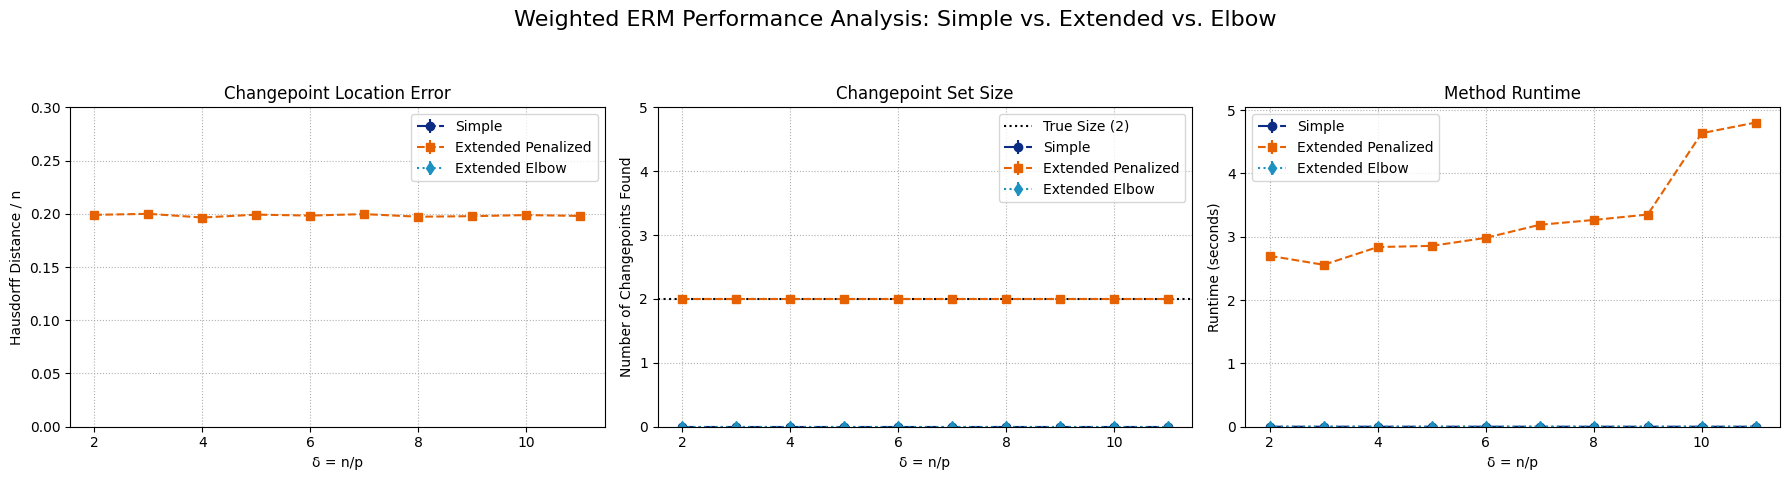

In [15]:
# -----------------------------------------------------------------------------
# 5. Plotting Results (This section remains unchanged)
# -----------------------------------------------------------------------------
print("Plotting results...")
PAL = ['#0c2c84', '#e66101', '#1d91c0', '#fdb863', '#7fcdbb', '#c7e9b4']
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Weighted ERM Performance Analysis: Simple vs. Extended vs. Elbow', fontsize=16)

# Hausdorff Distance Plot
ax = axs[0]
ax.errorbar(δ_list, np.mean(results['haus_simple'], axis=1), 
             yerr=np.std(results['haus_simple'], axis=1), 
             label="Simple", marker="o", ls="-.", c=PAL[0])
ax.errorbar(δ_list, np.mean(results['haus_ext'], axis=1), 
             yerr=np.std(results['haus_ext'], axis=1), 
             label="Extended Penalized", marker="s", ls="--", c=PAL[1])
ax.errorbar(δ_list, np.mean(results['haus_elbow'], axis=1), 
             yerr=np.std(results['haus_elbow'], axis=1), 
             label="Extended Elbow", marker="d", ls=":", c=PAL[2])
ax.set_ylim((0, 0.3))
ax.set_xlabel("δ = n/p")
ax.set_ylabel("Hausdorff Distance / n")
ax.set_title("Changepoint Location Error")
ax.legend()
ax.grid(True, linestyle=':')

# Changepoint Set Size Plot
ax = axs[1]
ax.errorbar(δ_list, np.mean(results['size_simple'], axis=1), 
             yerr=np.std(results['size_simple'], axis=1), 
             label="Simple", marker="o", ls="-.", c=PAL[0])
ax.errorbar(δ_list, np.mean(results['size_ext'], axis=1), 
             yerr=np.std(results['size_ext'], axis=1), 
             label="Extended Penalized", marker="s", ls="--", c=PAL[1])
ax.errorbar(δ_list, np.mean(results['size_elbow'], axis=1), 
             yerr=np.std(results['size_elbow'], axis=1), 
             label="Extended Elbow", marker="d", ls=":", c=PAL[2])
ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle=':', label=f'True Size ({len(fractional_chgpt_locations)})')
ax.set_ylim((0, L + 2))
ax.set_xlabel("δ = n/p")
ax.set_ylabel("Number of Changepoints Found")
ax.set_title("Changepoint Set Size")
ax.legend()
ax.grid(True, linestyle=':')

# Runtime Plot
ax = axs[2]
ax.errorbar(δ_list, np.mean(results['runtime_simple'], axis=1), 
             yerr=np.std(results['runtime_simple'], axis=1), 
             label="Simple", marker="o", ls="-.", c=PAL[0])
ax.errorbar(δ_list, np.mean(results['runtime_ext'], axis=1), 
             yerr=np.std(results['runtime_ext'], axis=1), 
             label="Extended Penalized", marker="s", ls="--", c=PAL[1])
ax.errorbar(δ_list, np.mean(results['runtime_elbow'], axis=1), 
             yerr=np.std(results['runtime_elbow'], axis=1), 
             label="Extended Elbow", marker="d", ls=":", c=PAL[2])
ax.set_ylim(bottom=0)
ax.set_xlabel("δ = n/p")
ax.set_ylabel("Runtime (seconds)")
ax.set_title("Method Runtime")
ax.legend()
ax.grid(True, linestyle=':')

plt.tight_layout(rect=[0, 0.03, 1, 0.93])
plt.show()


# Compare simple vs. extended WERM

In [ ]:
from WERM.signal_priors import GaussianSignal
import WERM.model
import WERM.general_fixed_point_eqns as fp
import WERM.performance_measures
import WERM.estimators
from WERM.config import η_to_ψ
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
from functools import partial
from tqdm.auto import tqdm  # Import tqdm for progress bars
import time
tqdm = partial(tqdm, position=0, leave=True)


# 1. Simulation Parameters
p = 500
L = 3 # num signals (L-1 changepoints)
noise_std = 0.01
δ_list = [2.0, 3.0, 4.0, 5.0]  # List of δ values
num_trials = 1
fractional_chgpt_locations = np.array([0.6])

# Loss Function (Least Squares)
M = lambda u, v: jnp.power(u - v, 2)

# 2. Results Storage for Comparison
results = {
    'haus_simple': np.zeros((len(δ_list), num_trials)),
    'size_simple': np.zeros((len(δ_list), num_trials)),
    'runtime_simple': np.zeros((len(δ_list), num_trials)),
    'haus_ext': np.zeros((len(δ_list), num_trials)),
    'size_ext': np.zeros((len(δ_list), num_trials)),
    'runtime_ext': np.zeros((len(δ_list), num_trials)),
    'haus_elbow': np.zeros((len(δ_list), num_trials)),
    'size_elbow': np.zeros((len(δ_list), num_trials)),
    'runtime_elbow': np.zeros((len(δ_list), num_trials)),
}

# 3. Main Loop
for i, δ in enumerate(tqdm(δ_list, desc="Iterating over δ")):
    n = int(δ * p)
    Delta = lambda n: int(n / 10)  # Window size for changepoint detection
    true_chgpt_locations_fn = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)

    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # Signal Prior Setup
    κ = 1.0
    B̃_cov = κ**2 * δ * np.eye(L)
    # Add some correlation to the covariance matrix
    # for j_ in range(L):
    #     for k_ in range(j_ + 1, L):
    #         B̃_cov[j_, k_] = B̃_cov[k_, j_] = κ**2 * δ * 0.00 * (j_ + k_) / L  # Example correlation
    signal_prior = GaussianSignal(B̃_cov)

    gamma_candidates = np.logspace(1, 10, 3)  # Candidates for gamma in ERM
    
    for j in tqdm(range(num_trials), desc=f"Trials for δ={δ}", leave=False):
        # --- Data Generation ---
        B̃ = signal_prior.sample(p)
        X = nprandom.normal(0, np.sqrt(1/n), (n, p))
        ε = nprandom.normal(0, 1, size=(n, )) * noise_std # noise vector
        
        true_chgpts = true_chgpt_locations_fn(n)
        # C_true = WERM.config.η_to_ψ(true_chgpts, n)
        Θ = X @ B̃
        y = jax.vmap(WERM.model.q_linear_model, in_axes=(0, 0, 0))(Θ, C_true, ε)
        
        # --- Run and Time Simple Weighted ERM ---
        start_time_simple = time.time()
        gamma_hat_1 = WERM.estimators.weighted_ermCV(X, y, M, L, Delta(n), gamma_candidates=gamma_candidates, L_is_upper_bound = True, brute_force=True)
        # gamma_hat_1 = 10
        opt_chgpt_loc_erm_simple = WERM.estimators.weighted_erm(
            X=X, y=y, M=M, L=L, Delta_n=Delta(n), gamma=gamma_hat_1,
            return_B_hat=False, brute_force = True
        )
        results['runtime_simple'][i, j] = time.time() - start_time_simple
        
        # --- Run and Time Weighted ERM Extended Penalized ---
        start_time_ext = time.time()
        gamma_hat_2 = WERM.estimators.weighted_erm_extended_penalizedCV(X, y, M, L, Delta(n), gamma_candidates=gamma_candidates, brute_force=True)
        # gamma_hat_2 = 10
        opt_chgpt_loc_erm_extended = WERM.estimators.weighted_erm_extended_penalized(
            X=X, y=y, M=M, L=L, Delta_n=Delta(n), gamma=gamma_hat_2,
            brute_force=True, min_window_size=300
        )
        results['runtime_ext'][i, j] = time.time() - start_time_ext

        # --- Run and Time Weighted ERM Extended Elbow ---
        start_time_elbow = time.time()
        opt_chgpt_loc_erm_extended_elbow = WERM.estimators.weighted_erm_extended_elbow(
            X=X, y=y, M=M, Delta_n=Delta(n), brute_force=True
        )
        results['runtime_elbow'][i, j] = time.time() - start_time_elbow
        
        # --- Store Results for All Three Methods ---
        # Simple Method
        results['haus_simple'][i, j] = (1/n) * WERM.performance_measures.hausdorff(opt_chgpt_loc_erm_simple, true_chgpts)
        results['size_simple'][i, j] = len(opt_chgpt_loc_erm_simple[opt_chgpt_loc_erm_simple != -1])
        # Extended Penalized Method
        results['haus_ext'][i, j] = (1/n) * WERM.performance_measures.hausdorff(opt_chgpt_loc_erm_extended, true_chgpts)
        results['size_ext'][i, j] = len(opt_chgpt_loc_erm_extended[opt_chgpt_loc_erm_extended != -1])
        # Extended Elbow Method
        results['haus_elbow'][i, j] = (1/n) * WERM.performance_measures.hausdorff(opt_chgpt_loc_erm_extended_elbow, true_chgpts)
        results['size_elbow'][i, j] = len(opt_chgpt_loc_erm_extended_elbow[opt_chgpt_loc_erm_extended_elbow != -1])


# 4. Plotting Results
PAL = ['#0c2c84', '#e66101', '#1d91c0', '#fdb863', '#7fcdbb', '#c7e9b4']
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Weighted ERM Performance Analysis: Simple vs. Extended vs. Elbow', fontsize=16)

# Hausdorff Distance Plot
ax = axs[0]
ax.errorbar(δ_list, np.mean(results['haus_simple'], axis=1), 
            yerr=np.std(results['haus_simple'], axis=1), 
            label="Simple", marker="o", ls="-.", c=PAL[0])
ax.errorbar(δ_list, np.mean(results['haus_ext'], axis=1), 
            yerr=np.std(results['haus_ext'], axis=1), 
            label="Extended Penalized", marker="s", ls="--", c=PAL[1])
ax.errorbar(δ_list, np.mean(results['haus_elbow'], axis=1), 
            yerr=np.std(results['haus_elbow'], axis=1), 
            label="Extended Elbow", marker="d", ls=":", c=PAL[2])
ax.set_ylim((0, 0.3))
ax.set_xlabel("δ = n/p")
ax.set_ylabel("Hausdorff Distance / n")
ax.set_title("Changepoint Location Error")
ax.legend()
ax.grid(True, linestyle=':')

# Changepoint Set Size Plot
ax = axs[1]
ax.errorbar(δ_list, np.mean(results['size_simple'], axis=1), 
            yerr=np.std(results['size_simple'], axis=1), 
            label="Simple", marker="o", ls="-.", c=PAL[0])
ax.errorbar(δ_list, np.mean(results['size_ext'], axis=1), 
            yerr=np.std(results['size_ext'], axis=1), 
            label="Extended Penalized", marker="s", ls="--", c=PAL[1])
ax.errorbar(δ_list, np.mean(results['size_elbow'], axis=1), 
            yerr=np.std(results['size_elbow'], axis=1), 
            label="Extended Elbow", marker="d", ls=":", c=PAL[2])
ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle=':', label=f'True Size ({len(fractional_chgpt_locations)})')
ax.set_ylim((0, L + 2))
ax.set_xlabel("δ = n/p")
ax.set_ylabel("Number of Changepoints Found")
ax.set_title("Changepoint Set Size")
ax.legend()
ax.grid(True, linestyle=':')

# Runtime Plot
ax = axs[2]
ax.errorbar(δ_list, np.mean(results['runtime_simple'], axis=1), 
            yerr=np.std(results['runtime_simple'], axis=1), 
            label="Simple", marker="o", ls="-.", c=PAL[0])
ax.errorbar(δ_list, np.mean(results['runtime_ext'], axis=1), 
            yerr=np.std(results['runtime_ext'], axis=1), 
            label="Extended Penalized", marker="s", ls="--", c=PAL[1])
ax.errorbar(δ_list, np.mean(results['runtime_elbow'], axis=1), 
            yerr=np.std(results['runtime_elbow'], axis=1), 
            label="Extended Elbow", marker="d", ls=":", c=PAL[2])
ax.set_ylim(bottom=0)
ax.set_xlabel("δ = n/p")
ax.set_ylabel("Runtime (seconds)")
ax.set_title("Method Runtime")
ax.legend()
ax.grid(True, linestyle=':')

plt.tight_layout(rect=[0, 0.03, 1, 0.93])
plt.show()

# Oldish

In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
import WERM.model as model
import WERM.general_fixed_point_eqns as fp
import WERM.M_est_fixed_point_eqns as M_est
import WERM.gof
import WERM.performance_measures
import WERM.marginals
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
import time
tqdm = partial(tqdm, position=0, leave=True)

p = 600
L = 2 # num signals. L-1 changepoints
noise_std = 1

δ_list = [1.8, 2.0, 2.5, 3.0, 4.0, 5.0]
# δ_list = [6.0, 7.0, 8.0, 9.0, 10.0]

# Least Squares Loss
M = lambda u, v: jnp.power(u - v, 2)

# Huber Loss
# def M(u, v, epsilon=1.35):
#     residual = u - v
#     abs_residual = jnp.abs(residual)
#     condition = abs_residual <= epsilon
#     squared_loss = 0.5 * jnp.square(residual)
#     linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
#     return jnp.where(condition, squared_loss, linear_loss)

# Logistic loss
# M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)
num_trials = 2

# chgpt_locations = np.array([0.3, 0.7])
fractional_chgpt_locations = np.array([0.6])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

erm_corr_arr = np.zeros((len(δ_list), num_trials, L))
erm_MSE_arr= np.zeros((len(δ_list), num_trials, L))
erm_haus_arr = np.zeros((len(δ_list), num_trials))
erm_size_arr = np.zeros((len(δ_list), num_trials))
erm_runtime = np.zeros((len(δ_list), num_trials))
theory_corr_arr = np.zeros((len(δ_list), num_trials, L))
theory_MSE_arr= np.zeros((len(δ_list), num_trials, L))
theory_haus_arr = np.zeros((len(δ_list), num_trials))
theory_size_arr = np.zeros((len(δ_list), num_trials))

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # --- Compute weights as marginals of prior --- #
    Δ = lambda n: 1
    π = np.zeros((L, n)) # Lxn matrix
    print("Computing marginals of prior...")
    for ℓ__ in range(1, L+1):
        for i__ in range(1, n+1):
            π[ℓ__-1, i__-1] = WERM.marginals.marginal_prior_approx_with_endpoints(
                l=ℓ__, i=i__, n=n, L=L, Delta=Δ(n), L_is_upper_bound=False
            )
    # Normalize π so that it sums to 1 for each signal (for stability of optimization)
    π = π / np.sum(π, axis=1, keepdims=True) # Lxn matrix

    # Gaussian Signal Prior
    κ = 1.0
    B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
    # B̃_cov = κ**2 * δ * np.array([[1.0, 0.0], [0.0, 1.0]]) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    key = jax.random.PRNGKey(0)

    for trial_num in tqdm(range(num_trials)):
        # Generate the observation vector Y
        X = np.random.normal(0, np.sqrt(1/n), (n, p))

        # ε = jax.random.t(key, 5, shape=(n, ))
        # ε = np.random.standard_t(5, size=(n, ))
        # ε = np.random.randn(n) * noise_std
        ε = np.random.uniform(0, 1, size=(n, ))

        Θ = X @ B̃
        # y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()
        y = jax.vmap(model.q_linear_model, in_axes=(0, 0, 0))(Θ, C_true, ε)
        # y = jax.vmap(model.q_logistic_model, in_axes = (0, 0, 0))(Θ, C_true, ε)

        # --- Run Weighted ERM and compare with the fixed point equations --- #
        B̂ = np.zeros((p, L))
        B̂_theory = np.zeros((p, L))

        # b, ν̃, κ̃ = fp.general_fp(M, ρ, δ, fractional_chgpt_locations, π, ε, n, model.q_linear_model) # Compute the fixed point solution to general problem
        # print("Computing fixed point solution...")
        # b, ν̃, κ̃ = fp.general_fp(M, ρ, δ, fractional_chgpt_locations, π, ε, n, model.q_logistic_model) # Compute the fixed point solution to general problem
        # print("b = ", b)
        # print("ν̃ = ", ν̃)
        # print("κ̃ = ", κ̃)
        # κ̃_sqrt = jnp.linalg.cholesky(κ̃ + 1e-12 * jnp.eye(L))  # stabilize

        # Time the execution of the ERM and save it
        start_time_erm = time.time()
        for ℓ_ in range(L): 

            # Compute metrics for the theory
            # G_sample = np.random.multivariate_normal(np.zeros((L, )), np.eye(L), size=(p,)) @ κ̃_sqrt.T
            # β̂_theory = B̃ @ ν̃[:, ℓ_] + δ**(1/2) * G_sample[:, ℓ_]
            # B̂_theory[:, ℓ_] = β̂_theory
            # theory_corr_arr[i, trial_num, ℓ_] = (WERM.norm_sq_corr(β̂_theory, B̃[:, ℓ_])) # For ERM compute once
            # theory_MSE_arr[i, trial_num, ℓ_] = (WERM.MSE(β̂_theory.flatten(), B̃[:, ℓ_]))

            # Compute the empirical risk minimization (ERM) solution and metrics
            print("Regressing on signal ", ℓ_)
            sample_weight = π[ℓ_, :] / np.sum(π[ℓ_, :]) # make it so that it sums to 1 (for stability of optimization)

            # Compute weighted ERM estimator
            empirical_risk = lambda β: jnp.multiply(M(X @ β, y), sample_weight).sum() / sample_weight.sum()
            res = scipy.optimize.minimize(empirical_risk, np.zeros(p), jac = jax.grad(empirical_risk), method='L-BFGS-B')
            print("ERM opt result: ", res) 
            β̂ = res.x
            B̂[:, ℓ_] = β̂
            erm_corr_arr[i, trial_num, ℓ_] = (WERM.norm_sq_corr(β̂, B̃[:, ℓ_])) # For ERM compute once
            erm_MSE_arr[i, trial_num, ℓ_] = (WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))


        ### --- Compute Change point estimates --- ###

        ## Compute Chgpt estimate for ERM
        PAL = ['#e66101', '#fdb863', '#f7f7f7', '#b2abd2', '#5e3c99']
        for ℓ in range(L):
            plt.plot(np.arange(n), M(X @ B̂[:, ℓ], y), c = PAL[-1 - ℓ_], alpha = 0.5, label="ERM β̂" + str(ℓ))
            plt.plot(np.arange(n), M(X @ B̂_theory[:, ℓ], y), c = PAL[-2 - ℓ_], alpha = 0.5, label="theory β̂" + str(ℓ))

        print("Optimizing gof erm...")
        opt_chgpt_loc_erm, opt_gof = WERM.gof.chgpt_gof_binary_seg_mem_eff(M, X @ B̂, y, n, L, Δ(n), γ=0.0, min_window_size=300, gof_opt_output=True)
        # opt_chgpt_loc_erm = WERM.gof.chgpt_gof_brute_force_mem_eff(M, X @ B̂, y, n, L, Δ(n), γ=1.0, batch_size=4096)
        # opt_chgpt_loc_theory, opt_gof = WERM.gof.chgpt_gof_binary_seg_mem_eff(M, X @ B̂_theory, y, n, L, Δ(n), γ=0.0, min_window_size=300, gof_opt_output=True)
        # opt_chgpt_loc_theory = WERM.gof.chgpt_gof_brute_force_mem_eff(M, X @ B̂, y, n, L, Δ(n), γ=1.0, batch_size=4096)
        print("WERM chpt estimate: ", opt_chgpt_loc_erm)
        # print("Theory chpt estimate: ", opt_chgpt_loc_theory)
        print("Done optimizing gof erm.")
        
        # Save the runtime
        erm_runtime[i, trial_num] = time.time() - start_time_erm

        # plot a vertical line at the optimal changepoint location
        [plt.axvline(x=loc, color='r', linestyle='-.', alpha = 0.8, label="ERM chgpt") for loc in opt_chgpt_loc_erm]
        # [plt.axvline(x=loc, color='y', linestyle='dotted', alpha = 0.8, label="ERM chgpt") for loc in opt_chgpt_loc_theory]
        [plt.axvline(x=c, color='g', linestyle='--', alpha = 0.8, label="True") for c in true_chgpt_locations(n)]

        erm_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(opt_chgpt_loc_erm, true_chgpt_locations(n)))
        # theory_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(opt_chgpt_loc_theory, true_chgpt_locations(n)))
        erm_size_arr[i, trial_num] = (len(opt_chgpt_loc_erm[opt_chgpt_loc_erm != -1]))
        theory_size_arr[i, trial_num] = (len(opt_chgpt_loc_erm[opt_chgpt_loc_erm != -1]))
    
        plt.legend()
        plt.show()

PAL = ['#0c2c84','#225ea8','#1d91c0','#41b6c4','#7fcdbb','#c7e9b4','#edf8b1','#ffffd9']
# Sqcorr plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_corr_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-.", c=PAL[ℓ_], alpha = 1.0)
    # plt.errorbar(δ_list, np.mean(theory_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(theory_corr_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " theory", marker="o", ls="-", c=PAL[ℓ_ + L], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_MSE_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-.", c=PAL[ℓ_], alpha = 1.0)
    # plt.errorbar(δ_list, np.mean(theory_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(theory_MSE_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " theory", marker="o", ls="-", c=PAL[ℓ_ + L], alpha = 1.0)
# plt.ylim((0, 2))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(erm_haus_arr, axis = 1), yerr = np.std(erm_haus_arr, axis = 1), label="erm", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.errorbar(δ_list, np.mean(theory_haus_arr, axis = 1), yerr = np.std(theory_haus_arr, axis = 1), label="theory", marker="o", ls="-", c=PAL[1], alpha = 1.0)
plt.ylim((0, 0.35))
plt.xlabel("δ")
plt.ylabel("Hausdorff")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(erm_size_arr, axis = 1), yerr = np.std(erm_haus_arr, axis = 1), label="erm", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.errorbar(δ_list, np.mean(theory_size_arr, axis = 1), yerr = np.std(theory_haus_arr, axis = 1), label="theory", marker="o", ls="-", c=PAL[1], alpha = 1.0)
plt.ylim((0, L + 1))
plt.xlabel("δ")
plt.ylabel("Size")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Runtime plots
# δ_arr = np.array([δ_list for _ in range(num_trials)])
# plt.errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = np.std(ERM_runtime, axis = 1), label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.xlabel("δ")
# plt.ylabel("Runtime")
# plt.legend()
# plt.show()

# Below is old code before new implementation

# Linear Model with Huber Loss 

In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
import WERM.model as model
import WERM.general_fixed_point_eqns as fp
import WERM.M_est_fixed_point_eqns as M_est
import WERM.gof
import WERM.performance_measures
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
import time
tqdm = partial(tqdm, position=0, leave=True)

p = 800
L = 2 # num signals. L-1 changepoints
noise_std = 1

# δ_list = [1.8, 2.0, 2.5, 3.0, 4.0, 5.0]
δ_list = [6.0, 7.0, 8.0, 9.0, 10.0]

# Least Squares Loss
# M = lambda u, v: jnp.power(u - v, 2)

# Huber Loss
# def M(u, v, epsilon=1.35):
#     residual = u - v
#     abs_residual = jnp.abs(residual)
#     condition = abs_residual <= epsilon
#     squared_loss = 0.5 * jnp.square(residual)
#     linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
#     return jnp.where(condition, squared_loss, linear_loss)

# Logistic loss
M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)
num_trials = 2

# chgpt_locations = np.array([0.3, 0.7])
fractional_chgpt_locations = np.array([0.6])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

erm_corr_arr = np.zeros((len(δ_list), num_trials, L))
erm_MSE_arr= np.zeros((len(δ_list), num_trials, L))
erm_haus_arr = np.zeros((len(δ_list), num_trials))
erm_size_arr = np.zeros((len(δ_list), num_trials))
erm_runtime = np.zeros((len(δ_list), num_trials))
theory_corr_arr = np.zeros((len(δ_list), num_trials, L))
theory_MSE_arr= np.zeros((len(δ_list), num_trials, L))
theory_haus_arr = np.zeros((len(δ_list), num_trials))
theory_size_arr = np.zeros((len(δ_list), num_trials))

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/100)
    Lmin = 2
    Lmax = 2
    # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if fractional_chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Gaussian Signal Prior
    κ = 1.0
    B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
    # B̃_cov = κ**2 * δ * np.array([[1.0, 0.0], [0.0, 1.0]]) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    key = jax.random.PRNGKey(0)

    for trial_num in tqdm(range(num_trials)):
        # Generate the observation vector Y
        X = np.random.normal(0, np.sqrt(1/n), (n, p))

        # ε = jax.random.t(key, 5, shape=(n, ))
        # ε = np.random.standard_t(5, size=(n, ))
        # ε = np.random.randn(n) * noise_std
        ε = np.random.uniform(0, 1, size=(n, ))

        Θ = X @ B̃
        # y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()
        # y = jax.vmap(model.q_linear_model, in_axes=(0, 0, 0))(Θ, C_true, ε)
        y = jax.vmap(model.q_logistic_model, in_axes = (0, 0, 0))(Θ, C_true, ε)

        # --- Run Weighted ERM and compare with the fixed point equations --- #
        B̂ = np.zeros((p, L))
        B̂_theory = np.zeros((p, L))

        # b, ν̃, κ̃ = fp.general_fp(M, ρ, δ, fractional_chgpt_locations, ϕ, ε, n, model.q_linear_model) # Compute the fixed point solution to general problem
        b, ν̃, κ̃ = fp.general_fp(M, ρ, δ, fractional_chgpt_locations, ϕ, ε, n, model.q_logistic_model) # Compute the fixed point solution to general problem
        print("b = ", b)
        print("ν̃ = ", ν̃)
        print("κ̃ = ", κ̃)
        κ̃_sqrt = jnp.linalg.cholesky(κ̃ + 1e-12 * jnp.eye(L))  # stabilize

        # Time the execution of the ERM and save it
        start_time_erm = time.time()
        for ℓ_ in range(L): 

            # Compute metrics for the theory
            G_sample = np.random.multivariate_normal(np.zeros((L, )), np.eye(L), size=(p,)) @ κ̃_sqrt.T
            β̂_theory = B̃ @ ν̃[:, ℓ_] + δ**(1/2) * G_sample[:, ℓ_]
            B̂_theory[:, ℓ_] = β̂_theory
            theory_corr_arr[i, trial_num, ℓ_] = (WERM.norm_sq_corr(β̂_theory, B̃[:, ℓ_])) # For ERM compute once
            theory_MSE_arr[i, trial_num, ℓ_] = (WERM.MSE(β̂_theory.flatten(), B̃[:, ℓ_]))

            # Compute the empirical risk minimization (ERM) solution and metrics
            print("Regressing on signal ", ℓ_)
            sample_weight = ϕ[ℓ_, :] / np.sum(ϕ[ℓ_, :]) # make it so that it sums to 1 (for stability of optimization)

            # Compute weighted ERM estimator
            empirical_risk = lambda β: jnp.multiply(M(X @ β, y), sample_weight).sum() / sample_weight.sum()
            res = scipy.optimize.minimize(empirical_risk, np.zeros(p), jac = jax.grad(empirical_risk), method='L-BFGS-B')
            print("ERM opt result: ", res) 
            β̂ = res.x
            B̂[:, ℓ_] = β̂
            erm_corr_arr[i, trial_num, ℓ_] = (WERM.norm_sq_corr(β̂, B̃[:, ℓ_])) # For ERM compute once
            erm_MSE_arr[i, trial_num, ℓ_] = (WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))


        ### --- Compute Change point estimates --- ###

        ## Compute Chgpt estimate for ERM
        PAL = ['#e66101', '#fdb863', '#f7f7f7', '#b2abd2', '#5e3c99']
        for ℓ in range(L):
            plt.plot(np.arange(n), M(X @ B̂[:, ℓ], y), c = PAL[-1 - ℓ_], alpha = 0.5, label="ERM β̂" + str(ℓ))
            plt.plot(np.arange(n), M(X @ B̂_theory[:, ℓ], y), c = PAL[-2 - ℓ_], alpha = 0.5, label="theory β̂" + str(ℓ))

        print("Optimizing gof erm...")
        opt_chgpt_loc_erm = WERM.gof.logistic_reg_opt_chgpt_gof(X @ B̂, y, η_arr, p_η_arr)
        # Note: in the following, X @ B̂_theory is equal to Θ̂_theory given that Θ_theory is stationary 
        opt_chgpt_loc_theory = WERM.gof.logistic_reg_opt_chgpt_gof(X @ B̂_theory, y, η_arr, p_η_arr)
        print("WERM chpt estimate: ", opt_chgpt_loc_erm)
        print("Theory chpt estimate: ", opt_chgpt_loc_theory)
        print("Done optimizing gof erm.")
        
        # Save the runtime
        erm_runtime[i, trial_num] = time.time() - start_time_erm

        # plot a vertical line at the optimal changepoint location
        [plt.axvline(x=loc, color='r', linestyle='-.', alpha = 0.8, label="ERM chgpt") for loc in opt_chgpt_loc_erm]
        [plt.axvline(x=loc, color='y', linestyle='dotted', alpha = 0.8, label="ERM chgpt") for loc in opt_chgpt_loc_theory]
        [plt.axvline(x=c, color='g', linestyle='--', alpha = 0.8, label="True") for c in true_chgpt_locations(n)]

        erm_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(opt_chgpt_loc_erm, true_chgpt_locations(n)))
        theory_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(opt_chgpt_loc_theory, true_chgpt_locations(n)))
        erm_size_arr[i, trial_num] = (len(opt_chgpt_loc_erm[opt_chgpt_loc_erm != -1]))
        theory_size_arr[i, trial_num] = (len(opt_chgpt_loc_erm[opt_chgpt_loc_erm != -1]))
    
        plt.legend()
        plt.show()

PAL = ['#0c2c84','#225ea8','#1d91c0','#41b6c4','#7fcdbb','#c7e9b4','#edf8b1','#ffffd9']
# Sqcorr plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_corr_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-.", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, np.mean(theory_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(theory_corr_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " theory", marker="o", ls="-", c=PAL[ℓ_ + L], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_MSE_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-.", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, np.mean(theory_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(theory_MSE_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " theory", marker="o", ls="-", c=PAL[ℓ_ + L], alpha = 1.0)
# plt.ylim((0, 2))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(erm_haus_arr, axis = 1), yerr = np.std(erm_haus_arr, axis = 1), label="erm", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
plt.errorbar(δ_list, np.mean(theory_haus_arr, axis = 1), yerr = np.std(theory_haus_arr, axis = 1), label="theory", marker="o", ls="-", c=PAL[1], alpha = 1.0)
plt.ylim((0, 0.35))
plt.xlabel("δ")
plt.ylabel("Hausdorff")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(erm_size_arr, axis = 1), yerr = np.std(erm_haus_arr, axis = 1), label="erm", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
plt.errorbar(δ_list, np.mean(theory_size_arr, axis = 1), yerr = np.std(theory_haus_arr, axis = 1), label="theory", marker="o", ls="-", c=PAL[1], alpha = 1.0)
plt.ylim((0, L + 1))
plt.xlabel("δ")
plt.ylabel("Size")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Runtime plots
# δ_arr = np.array([δ_list for _ in range(num_trials)])
# plt.errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = np.std(ERM_runtime, axis = 1), label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.xlabel("δ")
# plt.ylabel("Runtime")
# plt.legend()
# plt.show()

# Linear Model with change points: estimate ρ

In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
from WERM.model import *
from WERM.M_est_fixed_point_eqns import *
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)

p = 2000
L = 2 # num signals. L-1 changepoints

δ_list = [2.0]
noise_std = 0.2
M = lambda t: jnp.power(t, 2)

# chgpt_locations = np.array([0.3, 0.7])
fractional_chgpt_locations = np.array([0.5])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

erm_corr_list = [[] for ℓ_ in range(L)]
amp_corr_list = [[] for ℓ_ in range(L)]
erm_MSE_list = [[] for ℓ_ in range(L)]
amp_MSE_list = [[] for ℓ_ in range(L)]
theory_MSE_list = [[] for ℓ_ in range(L)]
comparison_corr_list = [[] for ℓ_ in range(L)]
comparison_MSE_list = [[] for ℓ_ in range(L)]

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/100)
    Lmin = 2
    Lmax = 2
    # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if fractional_chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Gaussian Signal Prior
    κ = 2.3
    B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    ρ̂ = ρ
    print("True ρ: ", ρ)

    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))
    Θ = X @ B̃
    y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()

    Δρ_arr = []
    # Ideas to fix: use the exact same noise vector, 
    for j in tqdm(range(10)): 
        # --- Run Weighted ERM and compare with the fixed point equations --- #
        B̂ = np.zeros((p, L))
        Θ̂_erm = np.zeros((n, L))
        Θ_t_erm = np.zeros((n, L))
        ν = np.zeros((L, L))
        κ_mat = np.zeros((L, L))

        for ℓ_ in range(L):

            # μ̃_arr, σ̃, μ_arr, σ = fp_linear_model_unif_prior(M, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
            # μ̃_arr, σ̃, μ_arr, σ = fp_linear_model_unif_prior(M, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
            # π = ϕ[ℓ_, :]
            π = np.ones(n) # Set to a trivial prior to test
            ε = np.random.normal(0, noise_std, n) # Sample noise equivalent to that of the model
            μ̃_arr, σ̃, μ_arr, σ, b = fp_lin_model(π, M, ρ̂, L, fractional_chgpt_locations, δ, n, ε)
            ν[:, ℓ_] = μ̃_arr
            κ_mat[ℓ_, ℓ_] = (σ̃)**2 / δ
            # print("σ̃ = ", σ̃)
            β̂_amp = B̃ @ μ̃_arr + σ̃ * np.random.normal(0, 1, p)

            # print("Regressing on signal ", ℓ_)
            sample_weight = π
            sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
            sk_lin_reg.fit(X, y, sample_weight = sample_weight)
            β̂ = sk_lin_reg.coef_

            B̂[:, ℓ_] = β̂
            Θ̂_erm[:, ℓ_] = X @ β̂
            print("### --- Debiasing... --- ###")
            Θ_t_erm[:, ℓ_] = debias_M_est(X @ β̂, y, b, π, X @ β̂)
            # loss = lambda u, v: M(u - v)
            # β̂_amp_algo, θ̂_amp_algo, β_t, θ_t = WERM.amp(X, y, n, p, π, loss, max_iter = 20)
            # Θ_t_erm[:, ℓ_] = θ_t
            
            # erm_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
            # amp_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp, B̃[:, ℓ_]))

            # comparison_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp.flatten(), β̂.flatten()))
            # comparison_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), β̂.flatten()))
            # erm_MSE_list[ℓ_].append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
            # amp_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), B̃[:, ℓ_]))
            # G = np.random.randn(p)
            # theory_MSE_list[ℓ_].append(WERM.MSE(σ̃ * G, np.zeros(p)))

        # Solve for ρ
        # Check whether \nu^T \rho \nu + \kappa is positive definite and whether ν is invertible
        rhs = ν.T @ ρ @ ν + κ_mat
        assert np.all(np.linalg.eigvals(rhs) > 0)

        # ρ̂ = np.linalg.inv(ν).T @ ((1/n * Θ_t_erm.T @ Θ_t_erm) - κ_mat) @ np.linalg.inv(ν) # Attempt to solve for ρ using a solver instead?
        ρ̂ = ρ
        lhs = (1/n * Θ_t_erm.T @ Θ_t_erm)
        print("lhs: ", lhs)
        print("rhs: ", rhs)
        print("lhs - rhs: ", lhs - rhs)
        print("ν: ", ν)
        print("κ_mat: ", κ_mat)

        print("ρ: ", ρ)
        print("ρ̂: ", ρ̂)
        print("Δρ: ", np.linalg.norm(ρ - ρ̂))
        print("ρ - ρ̂: ", ρ - ρ̂)
        Δρ_arr.append(np.linalg.norm(ρ - ρ̂))

    plt.plot(Δρ_arr)
    plt.title("Δρ")
    plt.show()

PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
for ℓ_ in range(L):
    # Sqcorr plots
    plt.errorbar(δ_list, erm_corr_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, amp_corr_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
    plt.ylim((0, 1))
    plt.xlabel("δ")
    plt.ylabel("Norm Sq Corr")
    plt.legend()
    plt.show()

    # MSE plots
    # plt.errorbar(δ_list, comparison_MSE_list[ℓ_], label="β" + str(ℓ_) + " comp", marker="D", ls="--", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, erm_MSE_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, amp_MSE_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
    # plt.errorbar(δ_list, theory_MSE_list[ℓ_], label="β" + str(ℓ_) + " theory", marker="x", ls="--", c=PAL[ℓ_], alpha = 1.0)
    plt.ylim((0, 2))
    plt.xlabel("δ")
    plt.ylabel("MSE")
    plt.legend()
    plt.show()

# Linear Model without change points: estimate γ

In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
from WERM.model import *
from WERM.M_est_fixed_point_eqns import *
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)

p = 2000
L = 1 # num signals. L-1 changepoints

δ_list = [3.0 for _ in range(30)]
noise_std = 0.2
# M = lambda t: jnp.power(t, 2)

def huber_loss(t, epsilon = 1.35):
    residual = t
    condition = jnp.abs(residual) < epsilon
    squared_loss = jnp.square(residual)
    linear_loss = 2 * epsilon * (jnp.abs(residual) - 0.5 * epsilon)
    return jnp.where(condition, squared_loss, linear_loss)
def M(t): return huber_loss(t)

erm_corr_list = [[] for ℓ_ in range(L)]
amp_corr_list = [[] for ℓ_ in range(L)]
erm_MSE_list = [[] for ℓ_ in range(L)]
amp_MSE_list = [[] for ℓ_ in range(L)]
theory_MSE_list = [[] for ℓ_ in range(L)]
comparison_corr_list = [[] for ℓ_ in range(L)]
comparison_MSE_list = [[] for ℓ_ in range(L)]

Δρ_trials_list = [[] for _ in δ_list]

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)

    # Gaussian Signal Prior
    γ_squared = 2.3
    B̃_cov = γ_squared * δ * np.eye(L) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    ρ̂ = np.eye(L)
    print("True ρ: ", ρ)

    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))
    Θ = X @ B̃
    ε = np.random.normal(0, noise_std, n) # Sample noise equivalent to that of the model
    y = Θ.flatten() + ε.flatten()

    Δρ_arr = [np.linalg.norm(ρ - ρ̂)]
    print("Δρ: ", np.linalg.norm(ρ - ρ̂))
    # Ideas to fix: use the exact same noise vector, 
    for j in tqdm(range(4)): 
        # --- Run Weighted ERM and compare with the fixed point equations --- #
        B̂ = np.zeros((p, L))
        Θ̂_erm = np.zeros((n, L))
        Θ_t_erm = np.zeros((n, L))
        ν = np.zeros((L, L))
        κ_mat = np.zeros((L, L))

        # π = ϕ[ℓ_, :]
        π = np.ones(n) # Set to a trivial prior to test
        ε = np.random.normal(0, noise_std, n) # Sample noise equivalent to that of the model
        fractional_chgpt_locations = np.array([])
        μ̃_arr, σ̃, μ_arr, σ, b = fp_lin_model(π, M, ρ̂, L, fractional_chgpt_locations, δ, n, ε)
        ν = μ̃_arr
        κ_mat = (σ̃)**2 / δ
        # print("σ̃ = ", σ̃)
        β̂_amp = B̃ @ μ̃_arr + σ̃ * np.random.normal(0, 1, p)

        # print("Regressing on signal ", ℓ_)
        # sample_weight = π
        # sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
        # sk_lin_reg.fit(X, y, sample_weight = sample_weight)
        # β̂ = sk_lin_reg.coef_

        # B̂[:, 0] = β̂
        # Θ̂_erm[:, 0] = X @ β̂
        print("### --- Debiasing... --- ###")
        # Run actual AMP
        loss = lambda u, v: M(u - v)
        β̂_amp_algo, θ̂_amp_algo, β_t, θ_t = WERM.amp(X, y, n, p, π, loss, max_iter = 20)
        Θ_t_erm[:, 0] = θ_t
        # Θ_t_erm[:, 0] = debias_M_est(X @ β̂, y, b, π, X @ β̂)

        # Solve for ρ
        # Check whether \nu^T \rho \nu + \kappa is positive definite and whether ν is invertible
        rhs = ν[0]**2 * ρ[0] + κ_mat
        # ρ̂ = np.linalg.inv(ν).T @ ((1/n * Θ_t_erm.T @ Θ_t_erm) - κ_mat) @ np.linalg.inv(ν) # Attempt to solve for ρ using a solver instead?
        ρ̂ = ((1/n * Θ_t_erm.T @ Θ_t_erm) - κ_mat) * (ν[0])**(-2) # Attempt to solve for ρ using a solver instead?
        # ρ̂ = ρ
        lhs = (1/n * Θ_t_erm.T @ Θ_t_erm)
        print("lhs: ", lhs)
        print("rhs: ", rhs)
        print("lhs - rhs: ", lhs - rhs)
        print("ν: ", ν)
        print("κ_mat: ", κ_mat)

        print("ρ: ", ρ)
        print("ρ̂: ", ρ̂)
        print("Δρ: ", np.linalg.norm(ρ - ρ̂))
        print("ρ - ρ̂: ", ρ - ρ̂)
        Δρ_arr.append(np.linalg.norm(ρ - ρ̂))

    plt.plot(Δρ_arr)
    plt.title("Δρ")
    plt.show()

    Δρ_trials_list[i] = (ρ - ρ̂)[0][0]

In [ ]:
# Δρ_trials_list = np.array(Δρ_trials_list)
# Plot a histogram of Δρ_trials_list
plt.hist(Δρ_trials_list)
plt.title("Δρ Trials")
plt.show()

print("Mean: ", np.mean(Δρ_trials_list))
print("Std: ", np.std(Δρ_trials_list))